In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Entradas binárias (X1, X2)
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Rótulos esperados: 1 apenas quando as entradas forem diferentes
y_xor = np.array([0, 1, 1, 0])

In [2]:
perceptron = Perceptron(max_iter=1000, random_state=42)
perceptron.fit(X_xor, y_xor)

pred_perceptron = perceptron.predict(X_xor)
acc_perceptron = accuracy_score(y_xor, pred_perceptron)

print(f"Predição do Perceptron> {pred_perceptron}")
print(f"Acurácia do Perceptron no XOR: {acc_perceptron * 100:.1f}%")

Predição do Perceptron> [0 0 0 0]
Acurácia do Perceptron no XOR: 50.0%


In [3]:
mlp_xor = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation="tanh",
    solver="lbfgs",
    max_iter=2000,
    random_state=42
)
mlp_xor.fit(X_xor, y_xor)

pred_mlp = mlp_xor.predict(X_xor)
acc_mlp = accuracy_score(y_xor, pred_mlp)

print(f"Predições da MLP: {pred_mlp}")
print(f"Acurácia da MLP no XOR: {acc_mlp * 100:.1f}%")

Predições da MLP: [0 1 1 0]
Acurácia da MLP no XOR: 100.0%


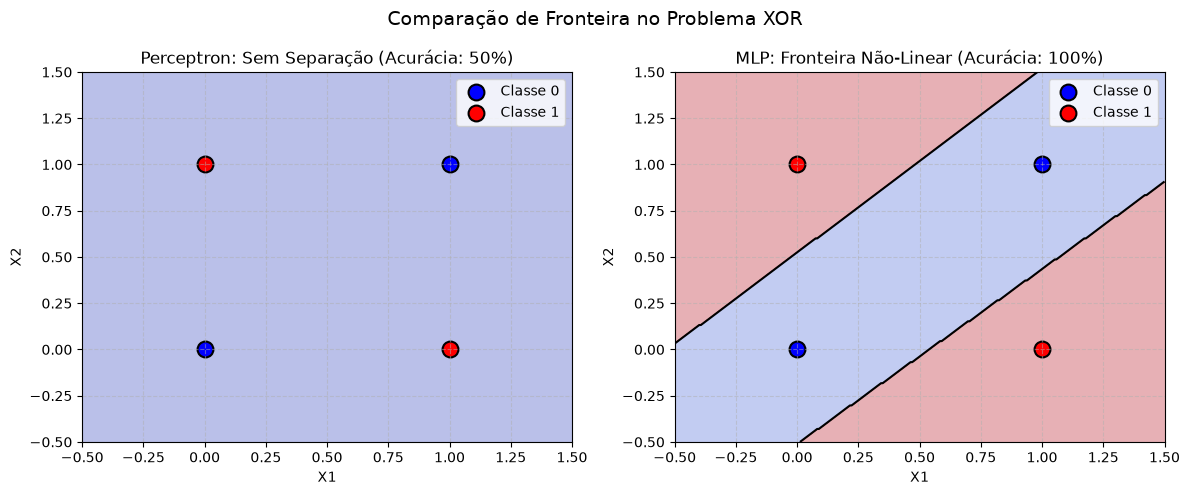

In [4]:
def plot_fronteira_comparativa(modelo_linear, modelo_mlp, X, y):
    # Grade de pontos cobrindo o plano cartesiano
    x_min, x_max = -0.5, 1.5
    y_min, y_max = -0.5, 1.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # --- Gráfico 1: Perceptron (Linear) ---
    z_perc = modelo_linear.predict(grid).reshape(xx.shape)
    axes[0].contourf(xx, yy, z_perc, alpha=0.35, cmap="coolwarm", vmin=0, vmax=1)
    axes[0].contour(xx, yy, z_perc, levels=[0.5], colors="black", linewidths=1.5, linestyles="--")
    axes[0].scatter(X[y == 0, 0], X[y == 0, 1], c="blue", s=130, edgecolors="black", linewidth=1.5, label="Classe 0")
    axes[0].scatter(X[y == 1, 0], X[y == 1, 1], c="red", s=130, edgecolors="black", linewidth=1.5, label="Classe 1")
    axes[0].set_title(f"Perceptron: Sem Separação (Acurácia: {accuracy_score(y, modelo_linear.predict(X)) * 100:.0f}%)")
    axes[0].set_xlabel("X1")
    axes[0].set_ylabel("X2")
    axes[0].set_xlim(x_min, x_max)
    axes[0].set_ylim(y_min, y_max)
    axes[0].legend(loc="upper right")
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # --- Gráfico 2: MLP (Não-Linear) ---
    z_mlp = modelo_mlp.predict(grid).reshape(xx.shape)
    axes[1].contourf(xx, yy, z_mlp, alpha=0.35, cmap="coolwarm", vmin=0, vmax=1)
    axes[1].contour(xx, yy, z_mlp, levels=[0.5], colors="black", linewidths=1.5)
    axes[1].scatter(X[y == 0, 0], X[y == 0, 1], c="blue", s=130, edgecolors="black", linewidth=1.5, label="Classe 0")
    axes[1].scatter(X[y == 1, 0], X[y == 1, 1], c="red", s=130, edgecolors="black", linewidth=1.5, label="Classe 1")
    axes[1].set_title(f"MLP: Fronteira Não-Linear (Acurácia: {accuracy_score(y, modelo_mlp.predict(X)) * 100:.0f}%)")
    axes[1].set_xlabel("X1")
    axes[1].set_ylabel("X2")
    axes[1].set_xlim(x_min, x_max)
    axes[1].set_ylim(y_min, y_max)
    axes[1].legend(loc="upper right")
    axes[1].grid(True, linestyle="--", alpha=0.5)

    plt.suptitle("Comparação de Fronteira no Problema XOR", fontsize=14)
    plt.tight_layout()
    plt.show()

plot_fronteira_comparativa(perceptron, mlp_xor, X_xor, y_xor)

In [5]:
import time
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Gera 1000 amostras com formato de duas luas
X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)

# Divião entre treino (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [6]:
arquiteturas = {
    "Subdimensionada (4,)": (4,), #1 camada oculta com 4 neuronios
    "Equilibrada (32, 16)": (32, 16),
    "Hiperdimensionada (256, 128, 64, 32)": (256, 128, 64, 32)
}

resultados = []

for nome, camadas in arquiteturas.items():
    modelo = MLPClassifier(
        hidden_layer_sizes=camadas,
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )

    # Medição do tempo de treinamento
    t_inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    t_fim = time.perf_counter()

    tempo_treino = t_fim - t_inicio

    # Cálculo da acurácia
    acc_treino = accuracy_score(y_train, modelo.predict(X_train))
    acc_teste = accuracy_score(y_test, modelo.predict(X_test))

    # Armazenamento dos resultados
    resultados.append({
        "Arquitetura": nome,
        "Tempo (s)": round(tempo_treino, 4),
        "Acurácia treino (%)": f"{acc_treino * 100:.2f}",
        "Acurácia teste (%)": f"{acc_teste * 100:.2f}",
        "Épocas": modelo.n_iter_
    })

import pandas as pd

df_resultados = pd.DataFrame(resultados)
print(df_resultados.to_string(index=False))

                         Arquitetura  Tempo (s) Acurácia treino (%) Acurácia teste (%)  Épocas
                Subdimensionada (4,)     0.2866               84.86              89.00     333
                Equilibrada (32, 16)     0.4132               94.29              97.33     315
Hiperdimensionada (256, 128, 64, 32)     0.6424               93.71              96.67      68


In [7]:
#Criando nosso modelo em arquivo

from pathlib import Path
import joblib

#Criando a pasta se não existir
Path("models").mkdir(exist_ok=True)
caminho_modelo = "models/mlp_moons.joblib"

#Salvar modelo treinado
joblib.dump(modelo, caminho_modelo)
print(f"Modelo salvo em: {caminho_modelo} ")

#Simulação de produção: carregar em nova versão
modelo_carregado = joblib.load(caminho_modelo)

#Novo ponto de teste
novas_amostras = np.array([
    [0.5, 0.2],
    [-0.5, 0.8]
])

previsoes = modelo_carregado.predict(novas_amostras)
probabilidades = modelo_carregado.predict_proba(novas_amostras)

for i, (pred, prob) in enumerate(zip(previsoes, probabilidades)):
    print(f"Amostra {i+1}: Classe prevista = {pred} | Probabilidade = {prob[pred] * 100:.2f}%")

Modelo salvo em: models/mlp_moons.joblib 
Amostra 1: Classe prevista = 1 | Probabilidade = 53.24%
Amostra 2: Classe prevista = 0 | Probabilidade = 99.99%
